# Amortized methods in geostatistics

In [1]:
import matplotlib
import matplotlib.pyplot as plt

import numpy as np

import random
from tqdm import tqdm
import time

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F

import torch_geometric
from torch_geometric.data import Data
from torch_geometric.nn import global_mean_pool

from torch_geometric.data import Dataset
from torch_geometric.loader import DataLoader
from torch_geometric.data import Batch

from torch_geometric.utils import to_scipy_sparse_matrix
from torch_geometric.nn.conv import MessagePassing
from torch_geometric.utils import scatter
from torch_geometric.nn import aggr

/home/aloret/PycharmProjects/Neural_ST_inference/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
from scipy.sparse.csgraph import connected_components
from scipy.spatial import cKDTree
from scipy.optimize import minimize
import scipy.linalg as linalg

In [4]:
import gstlearn as gl
import gstlearn.plot as gp
import gstlearn.document as gdoc
gdoc.setNoScroll()

<IPython.core.display.Javascript object>

In [5]:
device = torch.device("cuda:1" if torch.cuda.is_available() else "cpu")

## Simulation

### Sampling

In [6]:
def sampling_matern(lambdaParent,lambdaDaughter,radiusCluster):

    xMin = 0
    xMax = 1
    yMin = 0
    yMax = 1

    rExt = radiusCluster  
    xMinExt = xMin - rExt
    xMaxExt = xMax + rExt
    yMinExt = yMin - rExt
    yMaxExt = yMax + rExt

    xDeltaExt = xMaxExt - xMinExt
    yDeltaExt = yMaxExt - yMinExt
    areaTotalExt = xDeltaExt * yDeltaExt  

    numbPointsParent = np.random.poisson(areaTotalExt * lambdaParent)  
    
    xxParent = xMinExt + xDeltaExt * np.random.uniform(0, 1, numbPointsParent)
    yyParent = yMinExt + yDeltaExt * np.random.uniform(0, 1, numbPointsParent)

    numbPointsDaughter = np.random.poisson(lambdaDaughter, numbPointsParent) 
    numbPoints = sum(numbPointsDaughter)

    theta = 2 * np.pi * np.random.uniform(0, 1, numbPoints) 
    rho = radiusCluster * np.sqrt(np.random.uniform(0, 1, numbPoints)) 
    xx0 = rho * np.cos(theta)
    yy0 = rho * np.sin(theta)

    xx = np.repeat(xxParent, numbPointsDaughter)
    yy = np.repeat(yyParent, numbPointsDaughter)

    xx = xx + xx0
    yy = yy + yy0

    booleInside = ((xx >= xMin) & (xx <= xMax) & (yy >= yMin) & (yy <= yMax))
    xx = xx[booleInside]
    yy = yy[booleInside]

    # data = {'x1': xx, 'x2': yy}
    # sample = pd.DataFrame(data)

    sample = gl.Db()
    sample.addColumns(xx,"x1")
    sample.addColumns(yy,"x2")
    sample.setLocators(["x1","x2"],gl.ELoc.X)

    return sample


def grid():

    sample = gl.Db()
    sample.addColumns(np.repeat(np.linspace(0,1,100),100),"x1")
    sample.addColumns(np.tile(np.linspace(0,1,100),100),"x2")
    sample.setLocators(["x1","x2"],gl.ELoc.X)

    return sample 

theta_size = 2

In [7]:
def simulation_matern(sample, theta_range, theta_std, plot=False):

    model = gl.Model.createFromParam(type=gl.ECov.MATERN, range = theta_range*np.sqrt(8), param = 1, sill = theta_std**2)  # range is the practical range of Matérn with smoothness parameter = 1
    err = gl.simtub(None, sample, model, None, nbsimu=1, seed=0, nbtuba = 1000)

    if plot:
            fig, axs = plt.subplots(1, 1, figsize=(7, 7), constrained_layout=True)

            axs.scatter(sample['x1'], sample['x2'], c=sample['Simu'], s=8) 
        
            axs.set_xlabel('x1')
            axs.set_ylabel('x2')
            axs.set_title('Simu Values with Selected Points')

            axs.set_xlim([0, 1])
            axs.set_ylim([0, 1])
            axs.axis('equal')

            plt.show()

    return sample

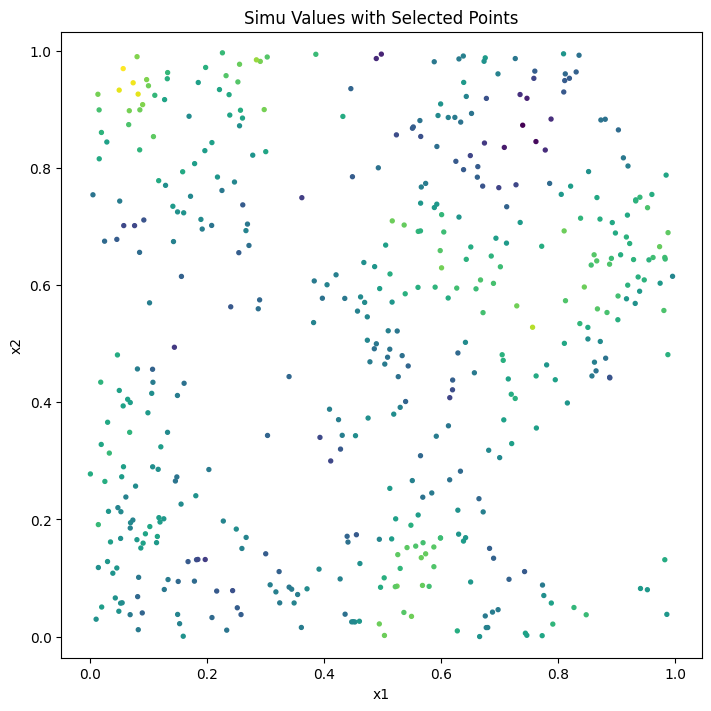


Data Base Characteristics

Data Base Summary
-----------------
File is organized as a set of isolated points
Space dimension              = 2
Number of Columns            = 3
Total number of samples      = 466

Variables
---------
Column = 0 - Name = x1 - Locator = x1
Column = 1 - Name = x2 - Locator = x2
Column = 2 - Name = Simu - Locator = z1

In [8]:
sample = sampling_matern(60,500//60,.1)
theta_range, theta_std = .1, 1.
simulation_matern(sample, theta_range, theta_std, plot=True)

In [9]:
def datamaker(constant_product, n, as_grid=False, range_min=.05, range_max=.5,std_min=.1, std_max=1.,lambdaParent_min=10,lambdaParent_max=60,radiusCluster = 0.15,log=False):

    datalist=[]

    range_list = np.random.uniform(range_min,range_max,n)
    std_list = np.random.uniform(std_min, std_max,n)
    lambdaParent = np.random.uniform(lambdaParent_min, lambdaParent_max,n)
    lambdaDaughter = constant_product / lambdaParent

    t = tqdm(range(0, n),total=n)

    for i in t:

        if as_grid :
            sample = grid() 
        else :
            sample = sampling_matern(lambdaParent[i],lambdaDaughter[i],radiusCluster)
        simu = simulation_matern(sample, range_list[i], std_list[i])

        theta = (range_list[i], std_list[i])

        datalist.append((simu,theta))

    return datalist

In [10]:
n_points = 1000
n_train = 100
n_test = 10

batch_size = 10 

In [11]:
sampling_train = datamaker(n_points, n_train, as_grid=False)

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 100/100 [00:10<00:00,  9.82it/s]


In [12]:
sampling_test = datamaker(n_points, n_test, as_grid=False)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 10/10 [00:00<00:00, 10.23it/s]


In [13]:
def baseline_mae(dataset):
    all_thetas = torch.stack([data[1] for data in dataset.datalist])
    
    theta_mean = all_thetas.mean(dim=0) 
    
    preds = theta_mean.unsqueeze(0).repeat(len(dataset), 1)
    
    mae = torch.mean(torch.abs(preds - all_thetas),dim=0)

    return mae, theta_mean

### Graphs

In [14]:
def create_edge_graph(sample, threshold=.4, max_neighbors=10):
    coords = sample[['x1', 'x2']]
    node_features = torch.tensor(sample[['Simu']], dtype=torch.float)

    nearest_neighbors = cKDTree(coords) 

    edge_sources = []
    edge_destinations = []
    edge_features = []

    for i, coord in enumerate(coords):
        neighbors = nearest_neighbors.query_ball_point(coord, r=threshold)
        neighbors = [j for j in neighbors if j != i]

        if len(neighbors) > max_neighbors:
            neighbors = np.random.choice(neighbors, max_neighbors, replace=False)

        dists = np.linalg.norm(coords[neighbors] - coord, axis=1)
            
        edge_sources.extend(np.repeat(i,len(neighbors))) # [i] * len(neighbors)
        edge_destinations.extend(neighbors) # neighbors.tolist()

        edge_sources.extend(neighbors)
        edge_destinations.extend(np.repeat(i,len(neighbors)))
        
        edge_features.extend(np.concatenate([dists, dists]))

    edge_index = torch.tensor([edge_sources, edge_destinations], dtype=torch.long)
    edge_attr = torch.tensor(edge_features, dtype=torch.float).unsqueeze(1) # .view(-1, 1)

    return Data(x=node_features.unsqueeze(-1), edge_index=edge_index, edge_attr=edge_attr, sizes=len(node_features))


In [15]:
class GraphDataset(Dataset):
    def __init__(self, datalist):
        self.datalist = datalist

    def __len__(self):
        return len(self.datalist)

    def __getitem__(self, idx):
        return self.datalist[idx]

In [16]:
def datamaker_graph(simu, threshold = 0.4,max_neighbors = 5):

    n = len(simu)
    datalist = []

    t = tqdm(range(0, n),total=n)

    for i in t:
        
        data = create_edge_graph(simu[i][0], threshold, max_neighbors)
        theta = torch.tensor(simu[i][1])

        datalist.append((data, theta))

    return GraphDataset(datalist)

In [17]:
dataset_graph = datamaker_graph(sampling_train)

loader_graph = DataLoader(dataset_graph, batch_size, shuffle=True)

dataset_graph[2]

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 100/100 [00:07<00:00, 13.77it/s]


(Data(x=[1240, 1], edge_index=[2, 12400], edge_attr=[12400, 1], sizes=1240),
 tensor([0.2845, 0.6487], dtype=torch.float64))

### Grid

In [18]:
def points_to_grid(sample, nb_bins=100):
    
    bin_size = 1.0 / nb_bins

    x1 = torch.tensor(sample['x1'], dtype=torch.float32)
    x2 = torch.tensor(sample['x2'], dtype=torch.float32)
    values = torch.tensor(sample['Simu'], dtype=torch.float32)
    
    ix = torch.clamp((x1 / bin_size).long(), max=nb_bins - 1)
    iy = torch.clamp((x2 / bin_size).long(), max=nb_bins - 1)

    flat_idx = ix * nb_bins + iy
    
    # value_flat = torch.zeros(nb_bins * nb_bins, dtype=torch.float32)
    # count_flat = torch.zeros(nb_bins * nb_bins, dtype=torch.float32)
        
    # value_flat.index_add_(0, flat_idx, values)
    # count_flat.index_add_(0, flat_idx, torch.ones_like(values))

    # mean_grid = torch.empty_like(value_flat)
    # mean_grid[:] = float('nan')
    # mask = count_flat > 0
    # mean_grid[mask] = value_flat[mask] / count_flat[mask]

    # return mean_grid.view(nb_bins, nb_bins)

    value_flat = torch.full((nb_bins * nb_bins,), float('nan'))

    unique_idx = flat_idx.unique()
    for idx in unique_idx:
        indices_in_cell = torch.where(flat_idx == idx)[0]
        chosen = indices_in_cell[torch.randint(0, len(indices_in_cell), (1,))]
        value_flat[idx] = values[chosen]

    return value_flat.view(nb_bins, nb_bins)

In [19]:
class GridSetDataset(Dataset):
    def __init__(self, datalist):
        self.datalist = datalist

    def __len__(self):
        return len(self.datalist)

    def __getitem__(self, idx):
                
        data = self.datalist[idx][0]
        mask = (~torch.isnan(data)).float()
        
        data = torch.nan_to_num(data, nan=0.)
        
        data = torch.stack([data, mask], dim=0) 
        # data = data.unsqueeze(0)
        
        theta = self.datalist[idx][1]
        
        return data, theta

In [20]:
def datamaker_grid(simu,bins = 100):

    n = len(simu)
    datalist = []
    
    t = tqdm(range(0, n),total=n)
    
    for i in t:

        data = points_to_grid(simu[i][0], bins)
        theta = torch.tensor(simu[i][1])
        
        datalist.append((data, theta))               
    
    return GridSetDataset(datalist)

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 100/100 [00:02<00:00, 46.30it/s]


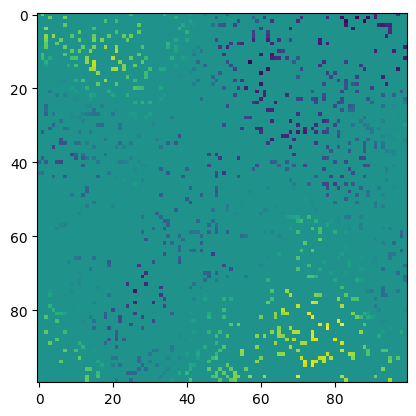

In [21]:
dataset_grid = datamaker_grid(sampling_train)

loader_grid = DataLoader(dataset_grid, batch_size, shuffle=True)

plt.imshow(dataset_grid[7][0][0])

## GNN

In [22]:
def w_first_half(distances, threshold=0.4, nb_intervals=10, epsilon=1e-5, std=0.00375):
    """
    exp(-(d_jj' _ µ_1)²/σ²), ..., exp(-(d_jj' _ µ_10)²/σ²)
    """
    
    if torch.max(distances) < epsilon or torch.max(distances) > threshold:
        raise ValueError(distances,threshold,"Distance should be within the range (0, threshold]")
    
    interval_length = threshold / nb_intervals
    interval_index = (distances / interval_length).to(torch.int)
    interval_index[interval_index == nb_intervals] -= 1

    means = torch.arange(interval_length/2,threshold,interval_length).tile((len(distances),1))
    
    res = distances.tile((1,nb_intervals))
    res = (res - means)**2 / (2 * std**2)
    
    return torch.exp(-res)


def w_first_half_old(distance, threshold=0.4, epsilon=1e-5):
    if distance < epsilon or distance > threshold:
        raise ValueError(distance,threshold,"Distance should be within the range (0, threshold]")
    
    interval_length = threshold / 10
    interval_index = int(distance / interval_length)
    if interval_index == 10:
        interval_index = 9
    
    one_hot = torch.zeros(10, device=device)
    one_hot[interval_index] = 1
    
    return one_hot

In [23]:
class w_second_half(nn.Module):
    """
    ω(d_jj'), MLP
    """
    def __init__(self, input_dim, hidden_dim, edge_output_dim):
        super(w_second_half, self).__init__()
        self.mlp = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, edge_output_dim)
        ).to(device) 

    def forward(self, x):
        return self.mlp(x)

In [24]:
class w_tilde(nn.Module):
    """
    w̃_j(s_j, s_j') = w_j(s_j, s_j') ⊘ Σ_j'' w_j(s_j, s_j'') 

    w(d_jj') = [exp(-(d_jj' _ µ_1)²/σ²), ..., exp(-(d_jj' _ µ_10)²/σ²), ω(d_jj')]
    """
    def __init__(self, in_channels, edge_hidden_dim, edge_output_dim, threshold=.4):
        super(w_tilde, self).__init__()
        
        self.edge_mlp = w_second_half(in_channels, edge_hidden_dim, edge_output_dim)
        self.threshold = threshold
    
    def forward(self, data):

        x, edge_index, edge_attr = data.x.to(device), data.edge_index.to(device), data.edge_attr.to(device)

        w_first = w_first_half(edge_attr, threshold=self.threshold).to(device)
        # w_first = torch.stack([w_first_half_old(d.item(),self.threshold) for d in edge_attr]).to(device)
        w_second = self.edge_mlp(edge_attr)
        w = torch.cat((w_first, w_second), dim=1) 

        d = scatter(w, edge_index[0], reduce = 'sum')  # sum over all neighbors
        dtilde = d[edge_index[0]]  
        
        mask = dtilde != 0
        replacement_tensor = torch.ones_like(mask, device=device) * 1e-5
        wtilde = torch.where(mask, w / dtilde, replacement_tensor) 
        
        data.edge_attr_wtilde = wtilde
        
        return data

In [25]:
class h(MessagePassing):  
    """
    h_j = g(Γ_1 @ h_(j-1) + Γ_2 @ ĥ_j + b), Convolution layer

    ĥ_j = Σ_j' w(d_jj') × ρ(h_j, h_j'), with h_j, h_j' from previous layer

    ρ(h_j, h_j') = |a h_j - (1-a) h_j'|^b
    """
    
    def __init__(self, hidden_channels, moovingvaluegamma1):
        super().__init__(aggr='add')
        
        self.a = nn.Parameter(torch.rand(1, device=device)) # a in [0, 1]
        self.b = nn.Parameter(torch.rand(1, device=device) + 1) # b > 0
        
        self.gamma1 = nn.Parameter(torch.rand(hidden_channels, moovingvaluegamma1, device=device))
        self.gamma2 = nn.Parameter(torch.rand(hidden_channels, hidden_channels, device=device))
        
        self.biax = nn.Parameter(torch.rand(hidden_channels,1, device=device))
    
    def forward(self, x: torch.Tensor, edge_index: torch.Tensor,
                edge_attr: torch.Tensor ) -> torch.Tensor:
        
        hbar = self.propagate(edge_index, x = x, edge_attr = edge_attr) 
        
        hbar = hbar.transpose(1,0)
        x = x.transpose(1,0)
        
        out = self.gamma1 @ x + self.gamma2 @ hbar + self.biax
        out = out.transpose(1,0)
        out = torch.nn.ReLU()(out).squeeze()

        return out

    def message(self, x_i, x_j, edge_attr: torch.Tensor) -> torch.Tensor:
        
        rho = (torch.abs(self.a * x_i - (1 - self.a) * x_j)) ** self.b

        return rho * edge_attr


In [26]:
class exp_final(nn.Module):
    def forward(self, x):
        return torch.exp(x)

class phi(nn.Module):
    """
    ɸ, MLP, mapping layer
    """
    def __init__(self, input_dim, hidden_dim, output_dim):
        super(phi, self).__init__()
        self.mlp = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, output_dim),
            # exp_final(), # In case we are looking to log of the targets
        )

    def forward(self, pooled_feature):
        device=pooled_feature.device
        out = self.mlp(pooled_feature.to(device))
        return out

In [27]:
class GNN_network(nn.Module):

    def __init__(self, in_channels, gamma1_1, gamma1_2, hidden_dim, edge_hidden_dim, edge_output_dim, threshold,mapping_hidden_dim, final_output_dim):# final_output_dim, mapping_hidden_dim, threshold):
        super(GNN_network, self).__init__()
        
        self.wtilde_initial = w_tilde(in_channels, edge_hidden_dim, edge_output_dim, threshold)
        self.special_conv1 = h(hidden_dim,gamma1_1)

        # We can repeat those two lines
        self.wtilde = w_tilde(in_channels, edge_hidden_dim, edge_output_dim, threshold) 
        self.special_conv2 = h(hidden_dim,gamma1_2)
        
        self.mapping = phi(hidden_dim, mapping_hidden_dim, final_output_dim)

    def forward(self, data):
        data = data.to(device)

        data = self.wtilde_initial(data)
        data.x = self.special_conv1(x=data.x, edge_index=data.edge_index, edge_attr= data.edge_attr_wtilde)
        
        data=self.wtilde(data)
        data.x=self.special_conv2(x=data.x, edge_index=data.edge_index, edge_attr= data.edge_attr_wtilde)
        
        pooled_graphs = global_mean_pool(data.x, data.pool_index.to(device)) 
        
        out = self.mapping(pooled_graphs)
        out = out.view(-1)
        
        return out

In [28]:
def train_gnn(model, optimizer, loader):
    
    model.train()
    MAE = torch.nn.L1Loss(reduction="mean")
    
    # sum_loss = torch.zeros(theta_size)
    sum_loss = torch.zeros((n_train,theta_size))

    for i, (batched_data, theta) in enumerate(loader):
        optimizer.zero_grad()

        batched_data, theta = batched_data.to(device), theta.to(device)

        pool_index = torch.repeat_interleave(
            torch.arange(len(batched_data.sizes), device=device),
            batched_data.sizes
        )
        batched_data.pool_index = pool_index

        current_batch_size = theta.size(0)

        theta = theta.view(current_batch_size, theta_size) 

        output = model(batched_data)
        output = torch.reshape(output,(current_batch_size,theta_size))
        
        batch_loss = MAE(output, theta)
        
        batch_loss.backward()
        optimizer.step()

        # sum_loss += torch.mean(torch.abs(output - theta),dim=0)
        sum_loss[i*len(theta):(i+1)*len(theta)] = torch.abs(output - theta)

    return sum_loss #/ len(loader)



In [29]:
model_graph = GNN_network(in_channels=1,
                 gamma1_1=1,
                 gamma1_2=20 ,
                 hidden_dim=20,
                 edge_hidden_dim=128,
                 edge_output_dim=10,
                 threshold=0.40,
                 mapping_hidden_dim=128,
                 final_output_dim=theta_size)

optimizer_graph = torch.optim.Adam(model_graph.parameters(), lr=1e-4)

Epoch 100/100: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 100/100 [03:49<00:00,  2.30s/it, loss=tensor([0.0957, 0.1227], grad_fn=<MeanBackward1>)]

Time to train : 229.67s


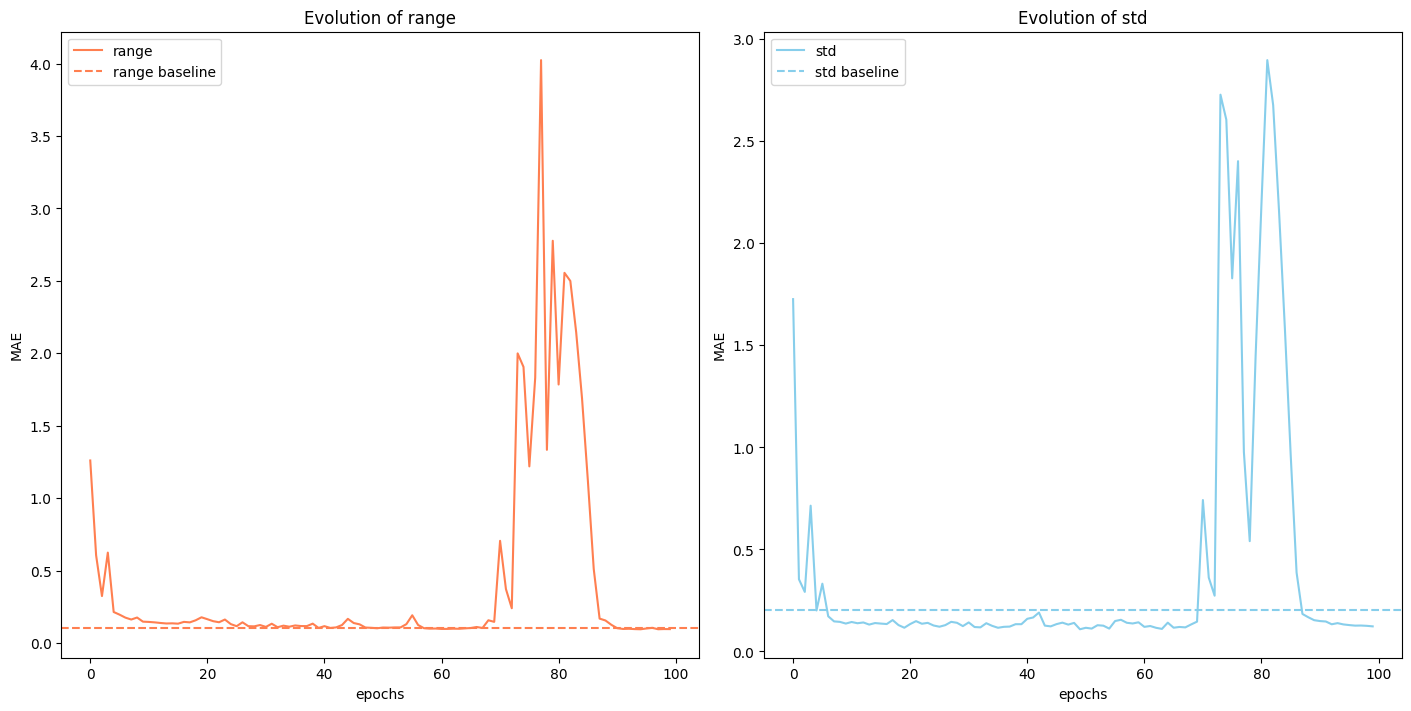

In [30]:
n_epochs = 100
all_loss_train_graph=torch.zeros((n_epochs, n_train,theta_size))

t = tqdm(range(0, n_epochs),total=n_epochs)

time_train_graph = time.time()

for epoch in t:
    
    loss = train_gnn(
        model_graph,
        optimizer_graph,
        loader_graph,
    )

    t.set_description(f"Epoch {epoch+1}/{n_epochs}")
    t.set_postfix(loss=f"{loss.mean(dim=0)}")
    all_loss_train_graph[epoch] = loss

time_train_graph = time.time() - time_train_graph

print(f"Time to train : {time_train_graph:.2f}s")

all_loss_train_graph = all_loss_train_graph.detach().numpy()

fig_gnn, ax = plt.subplots(1, 2, figsize=(14, 7), constrained_layout=True)
ax[0].plot(all_loss_train_graph.mean(axis=1)[:,0], 'coral', label='range')
ax[1].plot(all_loss_train_graph.mean(axis=1)[:,1], 'skyblue',label='std')

based, _ = baseline_mae(dataset_graph)
ax[0].axhline(based[0],color='coral', ls='--', label='range baseline')
ax[1].axhline(based[1],color='skyblue', ls='--', label='std baseline')

ax[0].set_title('Evolution of range')
ax[1].set_title('Evolution of std')
ax[0].set_xlabel('epochs')
ax[1].set_xlabel('epochs')
ax[0].set_ylabel('MAE')
ax[1].set_ylabel('MAE')
ax[0].legend()
ax[1].legend()

In [31]:
model_graph.eval()

loader_graph_test = DataLoader(
    datamaker_graph(sampling_test), 
    1, 
    shuffle=False
)

all_loss_test_graph = torch.zeros(len(sampling_test),theta_size)

time_test_graph = time.time() 

for i, (data_test, theta_test) in enumerate(loader_graph_test) : 
       
    pool_index = torch.repeat_interleave(
                torch.arange(len(data_test.sizes), device=device),
                data_test.sizes
            )
    data_test.pool_index = pool_index
    
    theta_test = theta_test.view(1, theta_size) 
    
    output = model_graph(data_test)
    output = torch.reshape(output,(1,theta_size))

    all_loss_test_graph[i] = torch.abs(output - theta_test)[0]

    # print(f"| RANGE {output[0,0]:.4f} - {theta_test[0,0]:.4f} = {abs(output[0,0]-theta_test[0,0]):.4f} | STD {output[0,1]:.4f} - {theta_test[0,1]:.4f} = {abs(output[0,1]-theta_test[0,1]):.4f} |")

time_test_graph = time.time() - time_test_graph

print(f"\nTime to test : {time_test_graph:.2f}s")

all_loss_test_graph = all_loss_test_graph.detach().numpy()

print("Test loss :", np.mean(all_loss_test_graph,axis=0), "±", np.std(all_loss_test_graph,axis=0))

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 10/10 [00:00<00:00, 12.53it/s]



Time to test : 0.14s
Test loss : [0.11993925 0.09147203] ± [0.06459937 0.0550714 ]


## CNN

In [32]:
class CNN_network(nn.Module):
    def __init__(self, in_channels=2, hidden=32, out_dim=2):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, hidden, 10, padding=1),
            nn.ReLU(),
            nn.Conv2d(hidden, hidden, 5, padding=1),
            nn.ReLU(),
        )
        self.pool = nn.AdaptiveAvgPool2d(1)  # ~vec(·) 
        self.dense = nn.Sequential(
            nn.Linear(hidden, 32),
            nn.ReLU(),
            nn.Linear(32, out_dim)  
        )


    def forward(self, x):
        
        # shape : (batch size, 2 = data+mask, grid_h, grib_v)
        h = self.conv(x)
        # shape : (batch size, hidden, grid_h, grib_v)
        h = self.pool(h).view(h.shape[0], -1)
        
        # shape : (batch size, 2 = data+mask)
        out = self.dense(h)
        
        # shape : (batch size, 2 = theta)
        return out

class CNN_network_nodense(nn.Module):
    def __init__(self, in_channels=2, hidden=32, out_dim=2):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, hidden, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(hidden, hidden, 3, padding=1),
            nn.ReLU(),
        )
        self.pool = nn.AdaptiveAvgPool2d(16)
        self.conv_out = nn.Sequential(
            nn.Conv2d(hidden, hidden//2, 4, padding=0,stride=4),
            nn.ReLU(),
            nn.Conv2d(hidden//2, 2, 4, padding=0,stride=4)
        )

    def forward(self, x):
        
        h = self.conv(x)
        
        out = self.pool(h)
        out = self.conv_out(out)
        out = out.view(h.shape[0], -1)
        
        return out

In [33]:
def train_cnn(model, optimizer, loader):
    
    model.train()
    MAE = torch.nn.L1Loss(reduction="mean")
    
    # sum_loss = torch.zeros(theta_size)
    sum_loss = torch.zeros((n_train,theta_size))

    for i, (x, theta) in enumerate(loader):
        optimizer.zero_grad()

        x, theta = x.to(device), theta.to(device)

        output = model(x)
        
        batch_loss = MAE(output, theta)
        
        batch_loss.backward()
        optimizer.step()

        # sum_loss += torch.mean(torch.abs(output - theta),dim=0)
        sum_loss[i*len(theta):(i+1)*len(theta)] = torch.abs(output - theta)

    return sum_loss #/ len(loader)



In [34]:
model_grid = CNN_network(in_channels=2).to(device)

optimizer_grid = torch.optim.Adam(model_grid.parameters(), lr=1e-4)

Epoch 100/100: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 100/100 [01:10<00:00,  1.41it/s, loss=tensor([0.1009, 0.1139], grad_fn=<MeanBackward1>)]

Time to train : 70.68s


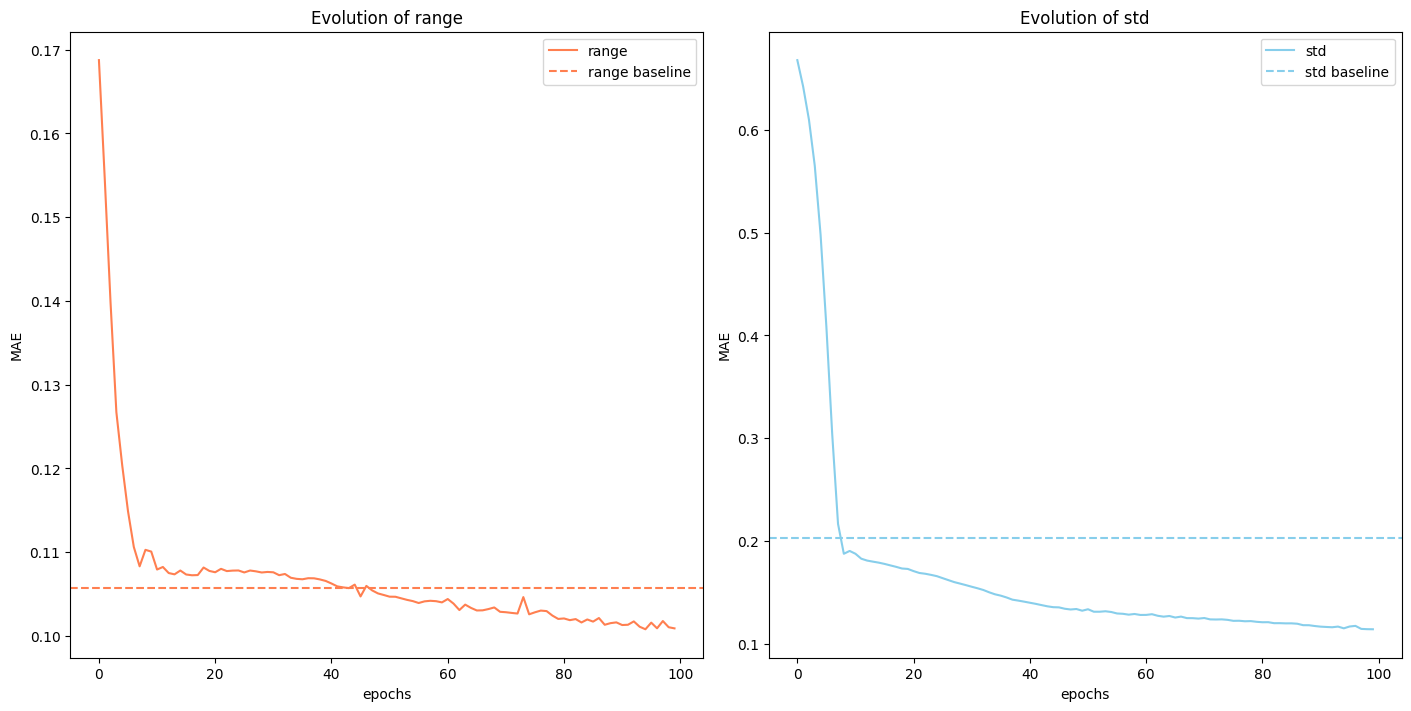

In [35]:
n_epochs = 100
all_loss_train_grid=torch.zeros((n_epochs, n_train,theta_size))

t = tqdm(range(0, n_epochs),total=n_epochs)

time_train_grid = time.time()

for epoch in t:
    
    loss = train_cnn(
        model_grid,
        optimizer_grid,
        loader_grid,
    )

    t.set_description(f"Epoch {epoch+1}/{n_epochs}")
    t.set_postfix(loss=f"{loss.mean(dim=0)}")
    all_loss_train_grid[epoch] = loss

time_train_grid = time.time() - time_train_grid

print(f"Time to train : {time_train_grid:.2f}s")

all_loss_train_grid = all_loss_train_grid.detach().numpy()

fig_cnn, ax = plt.subplots(1, 2, figsize=(14, 7), constrained_layout=True)
ax[0].plot(all_loss_train_grid.mean(axis=1)[:,0], 'coral', label='range')
ax[1].plot(all_loss_train_grid.mean(axis=1)[:,1], 'skyblue',label='std')

based, _ = baseline_mae(dataset_grid)
ax[0].axhline(based[0],color='coral', ls='--', label='range baseline')
plt.axhline(based[1],color='skyblue', ls='--', label='std baseline')

ax[0].set_title('Evolution of range')
ax[1].set_title('Evolution of std')
ax[0].set_xlabel('epochs')
ax[1].set_xlabel('epochs')
ax[0].set_ylabel('MAE')
ax[1].set_ylabel('MAE')
ax[0].legend()
ax[1].legend()

In [36]:
loader_grid_test = DataLoader(
    datamaker_grid(sampling_test), 
    1, 
    shuffle=False
)

all_loss_test_grid = torch.zeros(len(sampling_test),theta_size)

time_test_grid = time.time()

for i, (data_test, theta_test) in enumerate(loader_grid_test) : 
    
    output = model_grid(data_test)

    all_loss_test_grid[i] = torch.abs(output - theta_test)[0]

    # print(f"| RANGE {output[0,0]:.4f} - {theta_test[0,0]:.4f} = {abs(output[0,0]-theta_test[0,0]):.4f} | STD {output[0,1]:.4f} - {theta_test[0,1]:.4f} = {abs(output[0,1]-theta_test[0,1]):.4f} |")

time_test_grid = time.time() - time_test_grid

print(f"\nTime to test : {time_test_grid:.2f}s")

all_loss_test_grid = all_loss_test_grid.detach().numpy()

print("Test loss :", np.mean(all_loss_test_grid,axis=0), "±", np.std(all_loss_test_grid,axis=0))

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 10/10 [00:00<00:00, 37.60it/s]


Time to test : 0.04s
Test loss : [0.09960869 0.09368394] ± [0.08720449 0.08413578]


## Maximum likelyhood

In [37]:
def matern_covariance_from_coords(coords, range_theta, std_theta):
    db = gl.Db()
    db.addColumns(coords[:,0],"x1")
    db.addColumns(coords[:,1],"x2")
    db.setLocators(["x1","x2"],gl.ELoc.X)

    model = gl.Model.createFromParam(
        type=gl.ECov.MATERN,
        range=range_theta* np.sqrt(8),
        sill=std_theta**2,
        param=1.
    )

    cov = gl.evalCovMatSym(model,db)

    vals = cov.getValues()
    cov_np = np.array(vals).reshape(cov.getNRows(), cov.getNCols())

    return cov_np

In [38]:
def nll(theta, coords, values, eps=1e-6): 
    # https://soft.mines-paristech.fr/gstlearn/demos-latest/python/Tuto_LogLikelihood.html

    range_theta, std_theta = theta
    cov = matern_covariance_from_coords(coords, range_theta, std_theta)
    cov += eps * np.eye(cov.shape[0])

    L = linalg.cholesky(cov) 

    # solve Σ^{-1} @ values 
    alpha = linalg.cho_solve((L, False), values) 

    # Compute values.T @ Σ^{-1} @ values 
    quad = float(np.dot(values,alpha))

    # det term, https://math.stackexchange.com/questions/3158303/using-cholesky-decomposition-to-compute-covariance-matrix-determinant
    logdet = 2.0 * np.sum(np.log(np.diag(L)))

    return 0.5 * (logdet + quad + values.size * np.log(2.0 * np.pi))

In [39]:
def mle_matern(coords, values, theta0=(.2, .5)):

    def obj(theta):
        return nll(theta, coords, values)

    res = minimize(obj, theta0, method="Nelder-Mead", options={"maxiter":2000})
    return res.x, res

In [40]:
all_loss_test_ML = np.zeros((len(sampling_test),theta_size))

time_test_ML = time.time()

for i, (data_test, theta_test) in enumerate(sampling_test) : 

    output, _ = mle_matern(data_test[["x1","x2"]],data_test["Simu"])

    all_loss_test_ML[i] = np.abs(output - np.array(theta_test))

    print(f"| RANGE {output[0]:.4f} - {theta_test[0]:.4f} = {abs(output[0]-theta_test[0]):.4f} | STD {output[1]:.4f} - {theta_test[1]:.4f} = {abs(output[1]-theta_test[1]):.4f} |")

time_test_ML = time.time() - time_test_ML

print(f"\nTime to test : {time_test_ML:.2f}s")

print("Test loss :", np.mean(all_loss_test_ML,axis=0), "±", np.std(all_loss_test_ML,axis=0))

| RANGE 0.1586 - 0.1522 = 0.0064 | STD 0.4626 - 0.4216 = 0.0411 |
| RANGE 0.2855 - 0.4504 = 0.1650 | STD 0.4653 - 0.5332 = 0.0679 |
| RANGE 1.3731 - 0.4982 = 0.8749 | STD 0.9185 - 0.5488 = 0.3698 |
| RANGE 0.1709 - 0.1975 = 0.0266 | STD 0.4176 - 0.5030 = 0.0853 |
| RANGE 0.1693 - 0.1135 = 0.0557 | STD 0.9724 - 0.8319 = 0.1405 |
| RANGE 0.1258 - 0.1793 = 0.0535 | STD 0.5258 - 0.6318 = 0.1059 |
| RANGE 0.2726 - 0.3055 = 0.0329 | STD 0.4253 - 0.4949 = 0.0696 |
| RANGE 0.1253 - 0.2455 = 0.1202 | STD 0.5524 - 0.9140 = 0.3615 |
| RANGE 0.4953 - 0.2858 = 0.2095 | STD 0.7408 - 0.5139 = 0.2269 |
| RANGE 0.1470 - 0.1491 = 0.0021 | STD 0.4357 - 0.3974 = 0.0383 |

Time to test : 229.32s
Test loss : [0.15466094 0.15068459] ± [0.24890788 0.11946552]


## Conclusion

/tmp/ipykernel_47756/3301954724.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axs[0].boxplot(loss_range, labels=methods, patch_artist=True,
/tmp/ipykernel_47756/3301954724.py:21: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axs[1].boxplot(loss_std, labels=methods, patch_artist=True,


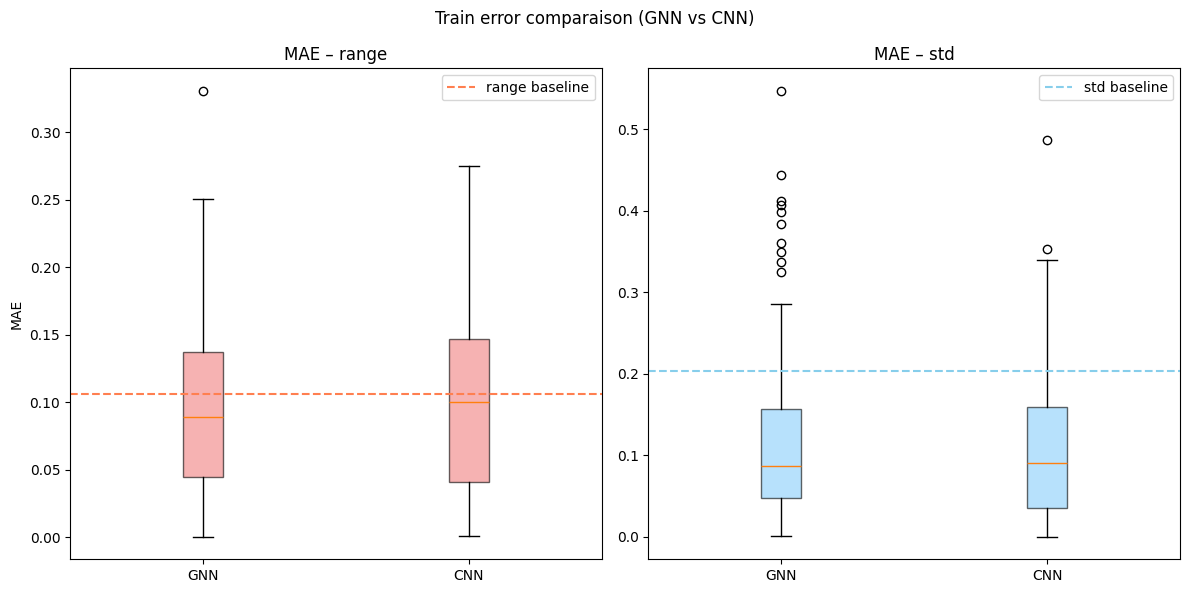

In [41]:
methods = ['GNN', 'CNN']

loss_range = [
    all_loss_train_graph[-1, :, 0],
    all_loss_train_grid[-1, :, 0],
]

loss_std = [
    all_loss_train_graph[-1, :, 1],
    all_loss_train_grid[-1, :, 1],
]

### Boxplot
fig_box_train, axs = plt.subplots(1, 2, figsize=(12, 6))

axs[0].boxplot(loss_range, labels=methods, patch_artist=True,
               boxprops=dict(facecolor='lightcoral', alpha=0.6))
axs[0].set_title("MAE – range")
axs[0].set_ylabel("MAE")

axs[1].boxplot(loss_std, labels=methods, patch_artist=True,
               boxprops=dict(facecolor='lightskyblue', alpha=0.6))
axs[1].set_title("MAE – std")

axs[0].axhline(based[0],color='coral', ls='--', label='range baseline')
axs[1].axhline(based[1],color='skyblue', ls='--', label='std baseline')

axs[0].legend()
axs[1].legend()

plt.suptitle("Train error comparaison (GNN vs CNN)")
plt.tight_layout()
plt.show()

/tmp/ipykernel_47756/1451531685.py:18: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axs[0].boxplot(loss_range, labels=methods, patch_artist=True,
/tmp/ipykernel_47756/1451531685.py:23: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axs[1].boxplot(loss_std, labels=methods, patch_artist=True,


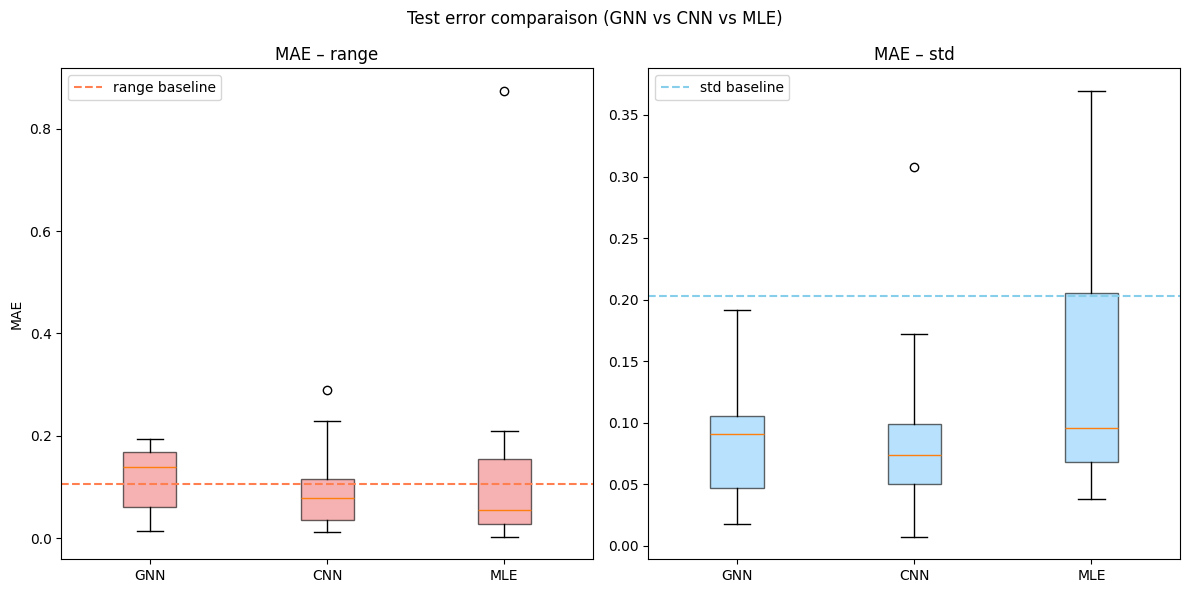

In [42]:
methods = ['GNN', 'CNN', 'MLE']

loss_range = [
    all_loss_test_graph[:, 0],
    all_loss_test_grid[:, 0],
    all_loss_test_ML[:, 0],
]

loss_std = [
    all_loss_test_graph[:, 1],
    all_loss_test_grid[:, 1],
    all_loss_test_ML[:, 1],
]

### Boxplot
fig_box_test, axs = plt.subplots(1, 2, figsize=(12, 6))

axs[0].boxplot(loss_range, labels=methods, patch_artist=True,
               boxprops=dict(facecolor='lightcoral', alpha=0.6))
axs[0].set_title("MAE – range")
axs[0].set_ylabel("MAE")

axs[1].boxplot(loss_std, labels=methods, patch_artist=True,
               boxprops=dict(facecolor='lightskyblue', alpha=0.6))
axs[1].set_title("MAE – std")

axs[0].axhline(based[0],color='coral', ls='--', label='range baseline')
axs[1].axhline(based[1],color='skyblue', ls='--', label='std baseline')

axs[0].legend()
axs[1].legend()

plt.suptitle("Test error comparaison (GNN vs CNN vs MLE)")
plt.tight_layout()
plt.show()

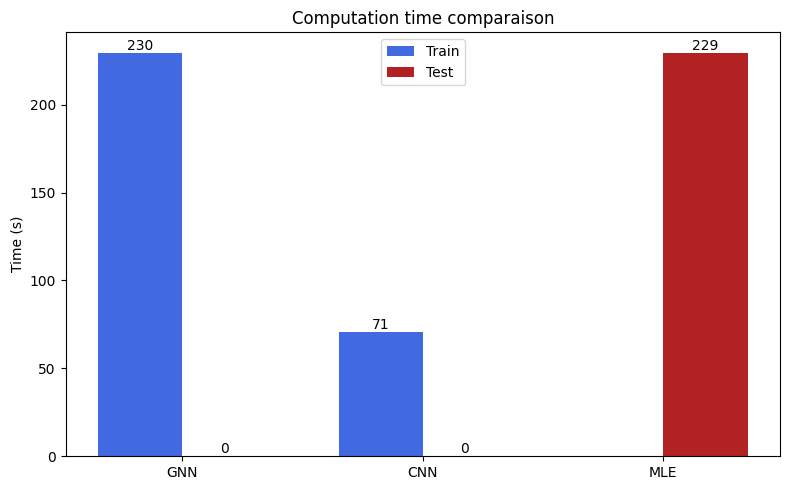

<Figure size 640x480 with 0 Axes>

In [43]:
### Time
train_times = [time_train_graph, time_train_grid, np.nan]  
test_times = [time_test_graph, time_test_grid, time_test_ML]

x = np.arange(len(methods))
width = 0.35

fig_time, ax = plt.subplots(figsize=(8, 5))
bar1 = ax.bar(x - width/2, train_times, width, label='Train', color='royalblue')
bar2 = ax.bar(x + width/2, test_times, width, label='Test', color='firebrick')

for rect in bar1 + bar2:
    height = rect.get_height()
    plt.text(rect.get_x() + rect.get_width() / 2.0, height, f'{height:.0f}', ha='center', va='bottom')

ax.set_xticks(x)
ax.set_xticklabels(methods)
ax.set_ylabel("Time (s)")
ax.set_title("Computation time comparaison")
ax.legend()

plt.tight_layout()
plt.show()

plt.savefig("myImagePDF.pdf", format="pdf", bbox_inches="tight")

In [44]:
import json
import os

all_loss_train = {"GNN":all_loss_train_graph.tolist(),"CNN":all_loss_train_grid.tolist()}
all_loss_test = {"GNN":all_loss_test_graph.tolist(),"CNN":all_loss_test_grid.tolist(),"MLE":all_loss_test_ML.tolist()}
path = f"results/{time_train_graph+time_train_grid+time_test_ML:.0f}time-{n_train}ntrain-{n_test}ntest-{n_points}npoints"

os.mkdir(path)
with open(path+"/all_loss", 'w') as f:
    json.dump({'train':all_loss_train, 'test':all_loss_test}, f)

In [45]:
# fig_box_train.savefig(path+"/score_train.pdf", format="pdf", bbox_inches="tight")
fig_box_train.savefig(path+"/score_train.png", format="png", bbox_inches="tight")
# fig_box_test.savefig(path+"/score_test.pdf", format="pdf", bbox_inches="tight")
fig_box_test.savefig(path+"/score_test.png", format="png", bbox_inches="tight")
# fig_time.savefig(path+"/time.pdf", format="pdf", bbox_inches="tight")
fig_time.savefig(path+"/time.png", format="png", bbox_inches="tight")

# fig_gnn.savefig(path+"/gnn.pdf", format="pdf", bbox_inches="tight")
fig_gnn.savefig(path+"/gnn_train_evolution.png", format="png", bbox_inches="tight")
# fig_cnn.savefig(path+"/cnn.pdf", format="pdf", bbox_inches="tight")
fig_cnn.savefig(path+"/cnn_train_evolution.png", format="png", bbox_inches="tight")
